In [51]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

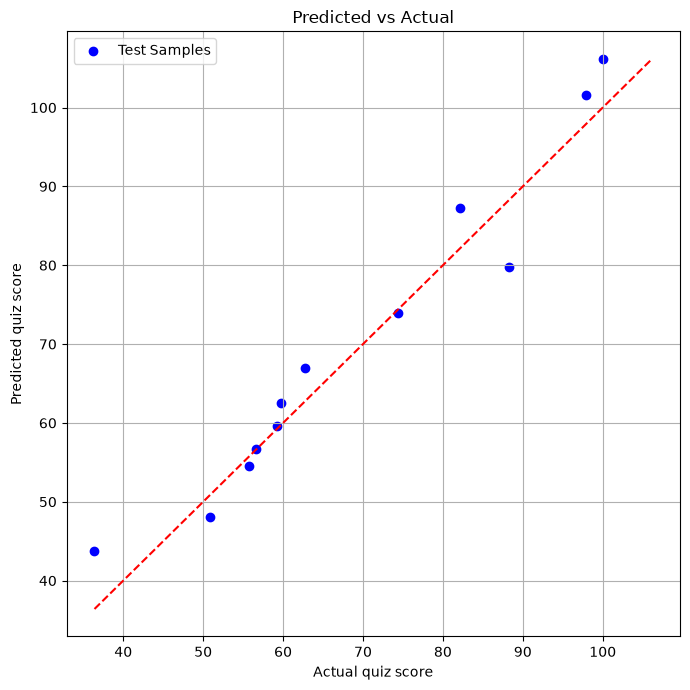

study_hours : 4.563458723887911
videos_watched : 0.734989182515771
practice_solved : 0.5859590510066357
Intercept: 21.403060901427345


In [52]:

quiz_data = pd.DataFrame({
    "study_hours": [
        4.8, 11.4, 8.9, 7.4, 2.3, 2.3, 1.2, 10.5, 7.4, 8.6,
        0.7, 11.7, 10.1, 2.9, 2.6, 2.6, 4.0, 6.5, 5.5, 3.8,
        7.5, 2.1, 3.9, 4.7, 5.7, 9.5, 2.8, 6.4, 7.3, 1.0,
        7.5, 2.5, 1.2, 11.4, 11.6, 9.8, 4.0, 1.6, 8.4, 5.6,
        1.9, 6.2, 0.9, 11.0, 3.5, 8.1, 4.1, 6.5, 6.8, 2.6,
        11.7, 9.4, 11.3, 10.8, 7.4, 11.1, 1.5, 2.8, 1.0, 4.2
    ],

    "videos_watched": [
        15, 12, 17, 14, 20, 23, 24, 12, 8, 14,
        12, 0, 24, 6, 8, 23, 0, 11, 7, 23,
        10, 18, 16, 7, 2, 2, 0, 4, 9, 6,
        8, 6, 8, 7, 11, 1, 0, 15, 22, 22,
        23, 4, 2, 11, 7, 21, 2, 0, 2, 4,
        14, 13, 2, 0, 4, 22, 13, 6, 8, 14
    ],

    "practice_solved": [
        14, 25, 12, 31, 38, 31, 3, 29, 36, 22,
        38, 14, 28, 35, 12, 31, 6, 21, 27, 1,
        5, 27, 27, 19, 29, 10, 27, 24, 38, 32,
        0, 26, 12, 2, 38, 5, 7, 26, 8, 36,
        32, 23, 14, 31, 31, 23, 11, 38, 1, 2,
        36, 16, 1, 1, 27, 22, 36, 31, 32, 0
    ],

    "quiz_score": [
        59.7, 94.2, 82.2, 83.1, 72.2, 62.8, 43.3, 97.3, 78.1, 88.6,
        61.2, 86.6, 97.9, 59.2, 43.3, 72.4, 48.4, 74.1, 66.6, 54.6,
        67.3, 55.2, 68.7, 54.5, 67.1, 69.7, 47.2, 62.9, 81.4, 50.7,
        64.3, 53.8, 44.5, 88.3, 100.0, 67.1, 36.4, 59.6, 85.4, 80.9,
        68.6, 69.8, 35.0, 100.0, 60.6, 82.2, 50.8, 77.4, 55.7, 32.3,
        100.0, 77.8, 76.1, 74.3, 74.4, 100.0, 55.3, 56.6, 44.6, 47.0
    ]
})

x = quiz_data[["study_hours", "videos_watched", "practice_solved"]]
y = quiz_data["quiz_score"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(x_train, y_train)
y_predict = model.predict(x_test)
mea = mean_absolute_error(y_test, y_predict)
msa = mean_squared_error(y_test, y_predict)
r2 = r2_score(y_test, y_predict)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_predict, color="blue", label="Test Samples")
lower = min(y_test.min(), y_predict.min())
upper = max(y_test.max(), y_predict.max())
plt.plot([lower, upper], [lower, upper], color="red", linestyle="--")
plt.xlabel("Actual quiz score")
plt.ylabel("Predicted quiz score")
plt.title("Predicted vs Actual")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

for feature, coefficient in zip(x.columns, model.coef_):
    print(feature, ":", coefficient)

print("Intercept:", model.intercept_)




In [53]:
print(quiz_data.shape)
print(x.shape)
print(y.shape)
print(len(x_train))
print(len(x_test))
print(y_predict)
print("MEA:", mea)
print("MSA:", msa)
print("R2:", r2_score)

(60, 4)
(60, 3)
(60,)
48
12
[ 62.53592723  66.96849775  43.75860915  87.27890757  59.55559308
  73.93350657  79.74333273  54.49051764 101.54058782  56.755411
  48.0287696  106.17990236]
MEA: 3.5647757861145517
MSA: 19.96130798119177
R2: <function r2_score at 0x7fab0d0a7ed0>
